# Notebook 3: Explaining the Model with SHAP

A prediction is more useful when we can say *why* the model made it. **SHAP** (SHapley Additive exPlanations) gives every word
in a message a score for how much it pushed the prediction towards (positive) or away from (negative) a category.

A few things that make SHAP easy to trust here:

- For a **linear model** like our Logistic Regression, SHAP values can be calculated exactly with a simple formula:
  `SHAP(word) = model weight of the word × (word's TF-IDF value in this message − its average TF-IDF value)`.
  This is exactly what `shap.LinearExplainer` computes, so we write it out ourselves. It's transparent and needs no extra library.
- SHAP values **add up**: the average model score plus all the word contributions equals the model's score for that message. We check this below.

We look at two levels:
- **Global**: which words matter most for each category overall
- **Local**: why one particular ticket got its prediction

In [1]:
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

TEXT, TARGET = config.TEXT, config.TARGET
FIG = config.FIGURES

model = joblib.load(config.MODELS / "tfidf_logreg.joblib")
tfidf = model.named_steps["tfidfvectorizer"]
clf = model.named_steps["logisticregression"]
words = tfidf.get_feature_names_out()
classes = list(clf.classes_)

tickets = pd.read_csv(config.PROCESSED / "tickets_clean.csv")
print("Model classes:", classes)
print("Number of word features:", len(words))

Model classes: ['account_access', 'billing_problem', 'bug', 'feature_request', 'how_to', 'other', 'performance', 'security_concern']
Number of word features: 411


## 1. Calculate the SHAP values

The "average message" (the background) is the mean TF-IDF vector over all 20,000 tickets.
Because the same 96 sentences repeat, we calculate SHAP once per unique sentence and remember how many tickets each one stands for.

In [2]:
X_all = tfidf.transform(tickets[TEXT])
background = np.asarray(X_all.mean(axis=0)).ravel()          # average TF-IDF value of every word

unique = tickets.groupby([TEXT, TARGET]).size().rename("tickets").reset_index()
X_u = tfidf.transform(unique[TEXT]).toarray()

# shap_values[i, c, j] = contribution of word j to class c for message i
shap_values = (X_u - background)[:, None, :] * clf.coef_[None, :, :]
base_values = clf.intercept_ + clf.coef_ @ background            # model score of the average message

print("SHAP array shape (messages, classes, words):", shap_values.shape)

SHAP array shape (messages, classes, words): (96, 8, 411)


In [3]:
# Check: base value + sum of SHAP values must equal the model's own score (the logit) for every message and class
model_scores = clf.decision_function(tfidf.transform(unique[TEXT]))
rebuilt = base_values + shap_values.sum(axis=2)
print("Largest difference between SHAP total and model score:", np.abs(model_scores - rebuilt).max())

Largest difference between SHAP total and model score: 1.9539925233402755e-14


The difference is essentially zero, so the explanations add up exactly to what the model computes.

**Optional cross-check with the `shap` library.** If you have it installed (`pip install shap`), this cell compares our numbers
with `shap.LinearExplainer`. If it isn't installed, the cell just says so.

In [ ]:
try:
    import shap
    explainer = shap.LinearExplainer(clf, shap.maskers.Independent(X_all.toarray()[:1000]))
    lib_values = np.array(explainer.shap_values(X_u))
    ours = shap_values.transpose(0, 2, 1)                       # (messages, words, classes)
    if lib_values.shape != ours.shape and lib_values.ndim == 3:
        lib_values = lib_values.transpose(1, 2, 0)              # older versions return (classes, messages, words)
    print("shap library installed. Correlation with our values:",
          round(np.corrcoef(lib_values.ravel(), ours.ravel())[0, 1], 4))
except ImportError:
    print("shap is not installed; skipping the cross-check (our exact formula is used).")
except Exception as e:
    print("shap cross-check could not run:", type(e).__name__, e)

shap is not installed; skipping the cross-check (our exact formula is used).


## 2. Global view: which words drive each category?

For each category we average the SHAP values of the tickets that belong to it (weighted by how many tickets use each sentence).
Words with a high average push tickets into that category.

In [1]:
rows = []
for c_idx, c in enumerate(classes):
    mask = unique[TARGET] == c
    weights = unique.loc[mask, "tickets"].values
    mean_shap = (shap_values[mask.values, c_idx, :] * weights[:, None]).sum(axis=0) / weights.sum()
    for j in np.argsort(-mean_shap)[:10]:
        if mean_shap[j] > 0:
            rows.append({"category": c, "term": words[j], "mean_shap": mean_shap[j]})
shap_global = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), classes):
    d = shap_global[shap_global["category"] == c].sort_values("mean_shap")
    ax.barh(d["term"], d["mean_shap"], color="steelblue")
    ax.set_title(c)
plt.suptitle("Top words pushing tickets into each category (mean SHAP value)", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "30_shap_global.png"); plt.show()

NameError: name 'classes' is not defined

Most of the top words are what a human agent would look for:

- **account_access**: "locked", "failed login", "login attempts"
- **billing_problem**: "plan", "charged twice", "subscription"
- **bug**: "saving", "not saving", "error" ("seeing an error")
- **feature_request**: "option", "customize", "add an"
- **security_concern**: "suspicious", "noticed suspicious", "vulnerability"
- **performance**: "timing out", "queries", "module"

But there's also a warning sign. Some filler words rank high too: "after" for account_access, "in the" and "are" for performance, "my changes" for bug.
They appear in only one category's sentences, so the model treats them as clues. That's a side effect of the dataset being built from a small set of sentences,
and it's one reason the model struggles with new wording. Product names (billing, notifications, ...) are *not* near the top, which is good.

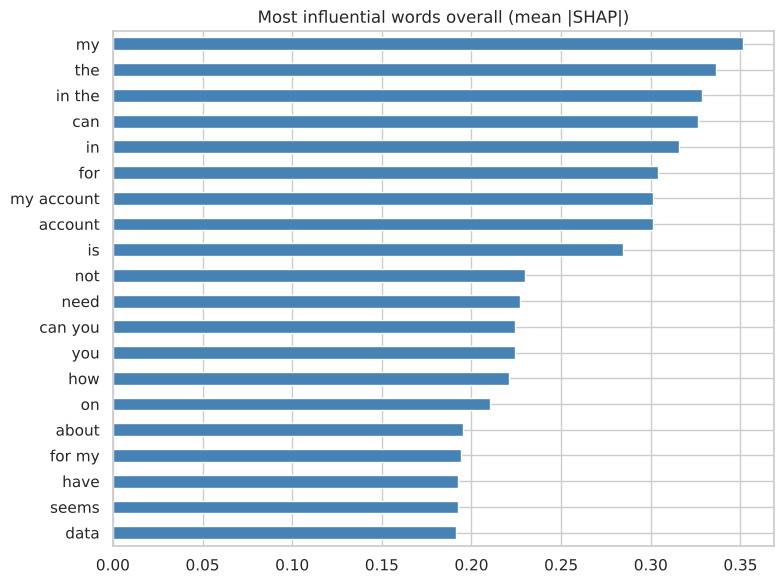

In [6]:
# Overall: which words matter most across all categories (mean absolute SHAP, weighted by tickets)
w = unique["tickets"].values
overall = (np.abs(shap_values).sum(axis=1) * w[:, None]).sum(axis=0) / w.sum()
top = pd.Series(overall, index=words).sort_values(ascending=False).head(20)

top.sort_values().plot.barh(figsize=(8, 6), color="steelblue")
plt.title("Most influential words overall (mean |SHAP|)")
plt.tight_layout(); plt.savefig(FIG / "31_shap_overall.png"); plt.show()

The overall ranking confirms the warning. The most influential words across all categories are common words like "my", "the", "in the", "can" and "for".
On their own they say nothing about the problem; they matter here only because each sentence template uses them differently.
With real, varied tickets this effect would shrink. A next step would be to test stop-word removal or sentence embeddings with more diverse training text.
(We tried removing stop words in testing; on this dataset it lowered macro F1, so we kept them.)

## 3. Local view: why did this ticket get this prediction?

We explain a few messages. For each one we show the words that pushed hardest towards the predicted category (positive)
and against it (negative). The new sentences were written by us and are not in the dataset.

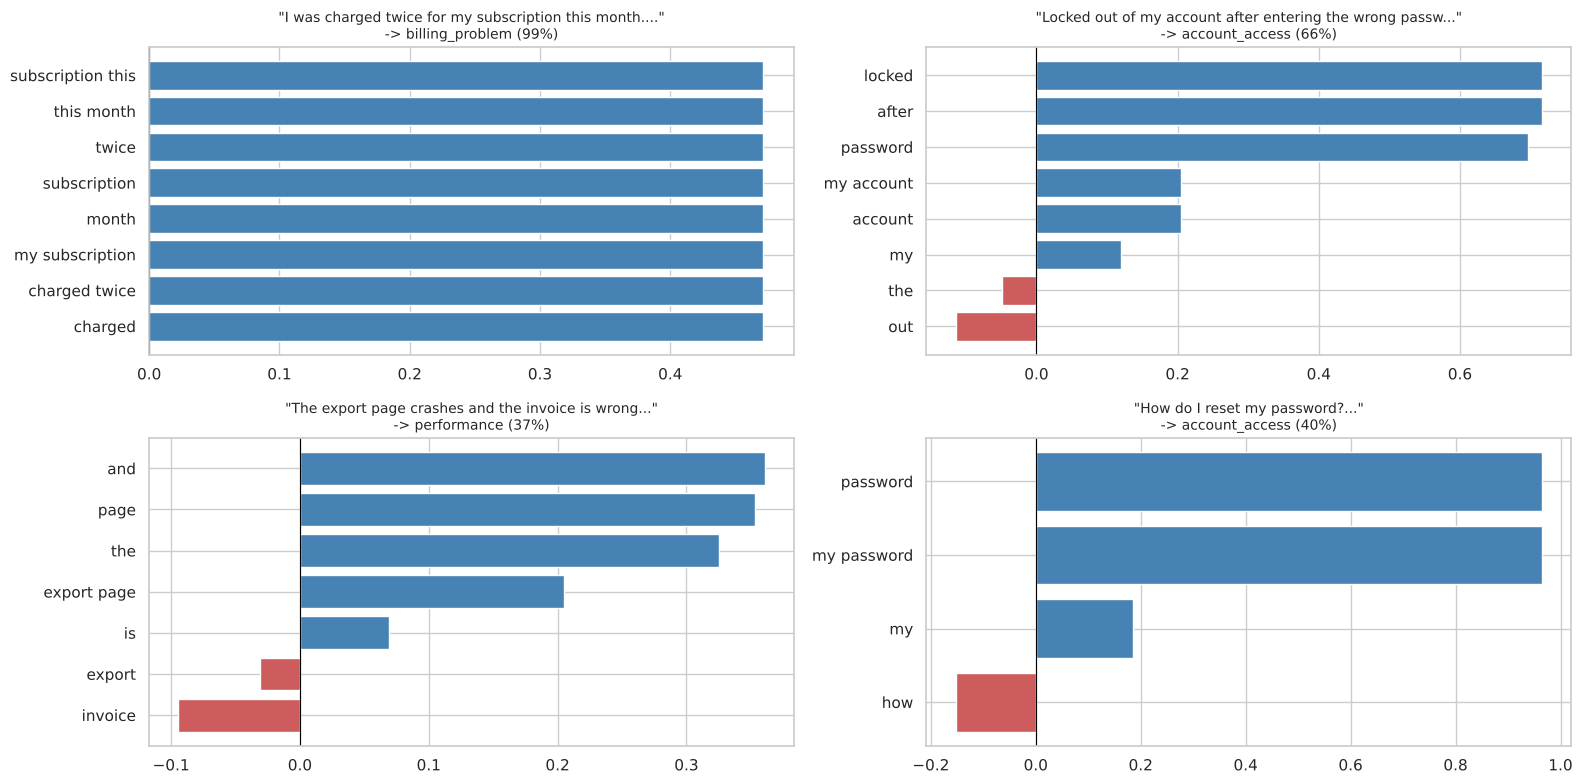

In [7]:
def explain(text, top_n=8):
    x = tfidf.transform([text]).toarray()[0]
    proba = model.predict_proba([text])[0]
    pred_idx = int(np.argmax(proba))
    contrib = (x - background) * clf.coef_[pred_idx]
    present = np.where(x > 0)[0]                         # only words that are in the message
    order = present[np.argsort(-np.abs(contrib[present]))][:top_n]
    table = pd.DataFrame({"term": words[order], "shap": contrib[order]})
    return classes[pred_idx], proba[pred_idx], table

samples = [
    "I was charged twice for my subscription this month.",
    "Locked out of my account after entering the wrong password too many times",
    "The export page crashes and the invoice is wrong",
    "How do I reset my password?",
]

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, text in zip(axes.ravel(), samples):
    label, conf, table = explain(text)
    table = table.sort_values("shap")
    ax.barh(table["term"], table["shap"], color=np.where(table["shap"] > 0, "steelblue", "indianred"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"\"{text[:55]}...\"\n-> {label} ({conf:.0%})", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "32_shap_local.png"); plt.show()

- **"charged twice"** (billing_problem, 99%): "charged twice", "subscription" and "this month" all push towards billing.
- **The lockout sentence** (account_access, 66%) is new wording, but "locked" and "password" carry it to the right category.
- **"export page crashes and the invoice is wrong"** (performance, 37%) mixes two problems. "page" pulls it towards the "page is very slow" sentences, while "invoice" pulls against.
  The low confidence correctly tells us a person should look at it.
- **"How do I reset my password?"** (account_access, 40%): "password" pushes towards access, while "how" pushes towards how_to. It's a genuinely ambiguous ticket,
  and the explanation shows exactly which words pull it each way.

This is what the dashboard shows next to each live prediction.

## 4. Save the explanations for the dashboard

In [8]:
local_rows = []
for i, row in unique.iterrows():
    label, conf, table = explain(row[TEXT])
    for _, t in table.iterrows():
        local_rows.append({TEXT: row[TEXT], "predicted": label, "confidence": conf, "term": t["term"], "shap": t["shap"]})
shap_local = pd.DataFrame(local_rows)

shap_global.to_csv(config.PROCESSED / "shap_global.csv", index=False)
shap_local.to_csv(config.PROCESSED / "shap_local.csv", index=False)
np.save(config.MODELS / "shap_background.npy", background)
print("Saved shap_global.csv:", shap_global.shape, "| shap_local.csv:", shap_local.shape, "| background vector")

Saved shap_global.csv: (80, 3) | shap_local.csv: (768, 5) | background vector


## Summary

- SHAP values were calculated exactly for the Logistic Regression model, and we confirmed they add up to the model's scores.
- **Globally**, each category is driven mostly by sensible key words (locked/login attempts for access, charged twice/subscription for billing, timing out for performance).
- Some filler words ("my", "the", "after") also carry weight because of how the synthetic sentences were written. This is a known limitation to mention.
- **Locally**, explanations show which words pushed a ticket each way, which makes mixed or vague tickets easy to understand.
- The background vector is saved, so the dashboard can explain brand-new tickets the same way.

Saved: `shap_global.csv`, `shap_local.csv`, `models/shap_background.npy`.